# 局所2D FFT＋ラジアルプロファイルによる画像全体解析

各局所位置 \((x,y)\) に対して `WINDOW_SIZE × WINDOW_SIZE` の正方形領域を取り出し，平均値除去，2D Hann窓，2D FFT，パワースペクトル，ラジアル平均，dB変換を行います．

最終的な特徴量マップは

```python
feature_map.shape == (Ny, Nx, N_RADIAL_BINS)
```

です．各位置 \((x,y)\) に `N_RADIAL_BINS` 次元の局所周波数特徴ベクトルを持たせます．

`scipy.fft` の `workers` とバッチFFTを使い，Jupyter上でもCPUマルチコアを利用します．


In [1]:
%matplotlib inline

import os
import platform
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from PIL import Image
from scipy import fft
from numpy.lib.stride_tricks import sliding_window_view

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = None

print("CPU logical cores:", os.cpu_count())


CPU logical cores: 16


In [2]:
def setup_japanese_font():
    os_name = platform.system()

    if os_name == "Darwin":
        candidates = ["Hiragino Sans", "Hiragino Kaku Gothic ProN", "YuGothic", "Arial Unicode MS"]
    elif os_name == "Windows":
        candidates = ["Yu Gothic", "Meiryo", "MS Gothic"]
    elif os_name == "Linux":
        candidates = ["Noto Sans CJK JP", "Noto Sans JP", "IPAexGothic", "IPAGothic", "TakaoGothic"]
    else:
        candidates = []

    installed_fonts = {f.name for f in fm.fontManager.ttflist}
    selected_font = next((name for name in candidates if name in installed_fonts), None)

    if selected_font:
        plt.rcParams["font.family"] = selected_font
        print("日本語フォント:", selected_font)
    else:
        print("日本語フォントが見つかりませんでした．")

    plt.rcParams["axes.unicode_minus"] = False

setup_japanese_font()


日本語フォント: Yu Gothic


In [5]:
# 解析設定
IMAGE_PATH = "C:\\work\\Visual_inspection\\data20260903\\data20260903\\image2.png"

WINDOW_SIZE = 128
STRIDE_X = 1
STRIDE_Y = 1

BATCH_SIZE = 64
FFT_WORKERS = -1

USE_HANN = True
N_RADIAL_BINS = WINDOW_SIZE // 2
RADIAL_FREQ_MAX = 0.5

DISPLAY_FREQ_MAX = 0.15
OUTPUT_NPZ = "radial_fft_feature_map.npz"

print("WINDOW_SIZE =", WINDOW_SIZE)
print("STRIDE_X =", STRIDE_X)
print("STRIDE_Y =", STRIDE_Y)
print("BATCH_SIZE =", BATCH_SIZE)
print("FFT_WORKERS =", FFT_WORKERS)
print("N_RADIAL_BINS =", N_RADIAL_BINS)
print("周波数分解能 =", 1.0 / WINDOW_SIZE, "cycles/pixel")


WINDOW_SIZE = 128
STRIDE_X = 1
STRIDE_Y = 1
BATCH_SIZE = 64
FFT_WORKERS = -1
N_RADIAL_BINS = 64
周波数分解能 = 0.0078125 cycles/pixel


In [6]:
img = Image.open(IMAGE_PATH)

img_rgb = np.asarray(img.convert("RGB"))
img_gray = np.asarray(img.convert("L"), dtype=np.float32)

height, width = img_gray.shape

print(f"画像サイズ: {width} × {height} pixel")

if WINDOW_SIZE > width or WINDOW_SIZE > height:
    raise ValueError("WINDOW_SIZEが画像サイズより大きいです．")


画像サイズ: 2048 × 1536 pixel


In [26]:
# 出力サイズとメモリ見積もり
nx = (width - WINDOW_SIZE) // STRIDE_X + 1
ny = (height - WINDOW_SIZE) // STRIDE_Y + 1

output_bytes = ny * nx * N_RADIAL_BINS * np.dtype(np.float32).itemsize

print("出力形状:", (ny, nx, N_RADIAL_BINS))
print("位置数:", ny * nx)
print("概算出力メモリ: %.1f MB" % (output_bytes / 1024**2))
print("概算出力メモリ: %.2f GB" % (output_bytes / 1024**3))


出力形状: (353, 481, 64)
位置数: 169793
概算出力メモリ: 41.5 MB
概算出力メモリ: 0.04 GB


In [8]:
# Hann窓とラジアル平均用の行列を事前計算
if USE_HANN:
    hann_1d = np.hanning(WINDOW_SIZE).astype(np.float32)
    HANN_2D = np.outer(hann_1d, hann_1d).astype(np.float32)
else:
    HANN_2D = np.ones((WINDOW_SIZE, WINDOW_SIZE), dtype=np.float32)

center = WINDOW_SIZE // 2
yy_fft, xx_fft = np.indices((WINDOW_SIZE, WINDOW_SIZE))

radius_pixel = np.sqrt((xx_fft - center) ** 2 + (yy_fft - center) ** 2)
radius_freq = radius_pixel / WINDOW_SIZE

radial_edges = np.linspace(0.0, RADIAL_FREQ_MAX, N_RADIAL_BINS + 1)
radial_centers = (radial_edges[:-1] + radial_edges[1:]) / 2.0

radial_index = np.digitize(radius_freq.ravel(), radial_edges) - 1

valid = (radial_index >= 0) & (radial_index < N_RADIAL_BINS)
counts = np.bincount(radial_index[valid], minlength=N_RADIAL_BINS).astype(np.float32)
counts[counts == 0] = 1.0

RADIAL_MATRIX = np.zeros(
    (WINDOW_SIZE * WINDOW_SIZE, N_RADIAL_BINS),
    dtype=np.float32
)

valid_flat_indices = np.flatnonzero(valid)

RADIAL_MATRIX[
    valid_flat_indices,
    radial_index[valid]
] = 1.0 / counts[radial_index[valid]]

print("RADIAL_MATRIX shape:", RADIAL_MATRIX.shape)
print("RADIAL_MATRIX memory: %.1f MB" % (RADIAL_MATRIX.nbytes / 1024**2))


RADIAL_MATRIX shape: (16384, 64)
RADIAL_MATRIX memory: 4.0 MB


In [9]:
def calc_radial_spectrum_batch(patches):
    '''
    patches:
        shape = (B, WINDOW_SIZE, WINDOW_SIZE)

    return:
        shape = (B, N_RADIAL_BINS)
    '''

    patches = np.asarray(patches, dtype=np.float32)

    # 各局所領域ごとに平均値を除去
    fft_input = patches - patches.mean(axis=(1, 2), keepdims=True)

    # 2D Hann窓
    fft_input *= HANN_2D[None, :, :]

    # バッチ2D FFT
    fft_result = fft.fft2(
        fft_input,
        axes=(-2, -1),
        workers=FFT_WORKERS
    )

    fft_result = fft.fftshift(
        fft_result,
        axes=(-2, -1)
    )

    power = (np.abs(fft_result) ** 2).astype(np.float32)

    # ラジアル平均
    power_flat = power.reshape(power.shape[0], -1)
    radial_mean = power_flat @ RADIAL_MATRIX

    # dB
    radial_db = (
        10.0 * np.log10(radial_mean + 1e-12)
    ).astype(np.float32)

    return radial_db


In [10]:
def calc_one_y_band(img_gray, y0):
    '''
    1本の横帯について，x方向に局所窓をstride付きで走査し，
    まとめてバッチFFTする．
    '''

    band = img_gray[y0:y0 + WINDOW_SIZE, :]

    windows = sliding_window_view(
        band,
        window_shape=WINDOW_SIZE,
        axis=1
    )

    # (WINDOW_SIZE, Nx, WINDOW_SIZE) → (Nx, WINDOW_SIZE, WINDOW_SIZE)
    windows = np.moveaxis(windows, 1, 0)

    # x方向stride
    windows = windows[::STRIDE_X]

    n_x = windows.shape[0]

    result = np.empty(
        (n_x, N_RADIAL_BINS),
        dtype=np.float32
    )

    for start in range(0, n_x, BATCH_SIZE):
        end = min(start + BATCH_SIZE, n_x)

        result[start:end] = calc_radial_spectrum_batch(
            windows[start:end]
        )

    return result


In [20]:
STRIDE_X = 4
STRIDE_Y = 4

def calc_full_feature_map(img_gray):
    '''
    画像全体を解析する．

    return:
        feature_map : (Ny, Nx, N_RADIAL_BINS)
        x_centers
        y_centers
        radial_centers
    '''
    
    h, w = img_gray.shape

    y0_list = np.arange(
        0,
        h - WINDOW_SIZE + 1,
        STRIDE_Y,
        dtype=int
    )

    x0_list = np.arange(
        0,
        w - WINDOW_SIZE + 1,
        STRIDE_X,
        dtype=int
    )

    y_centers = y0_list + WINDOW_SIZE / 2
    x_centers = x0_list + WINDOW_SIZE / 2

    feature_map = np.empty(
        (
            len(y0_list),
            len(x0_list),
            N_RADIAL_BINS
        ),
        dtype=np.float32
    )

    iterator = y0_list
    if tqdm is not None:
        iterator = tqdm(y0_list, desc="局所FFT")

    for iy, y0 in enumerate(iterator):
        feature_map[iy] = calc_one_y_band(img_gray, y0)

    return feature_map, x_centers, y_centers, radial_centers


In [21]:
# 画像全体を計算
# stride=1では画像サイズによって時間とメモリを使います．
# 最初はSTRIDE_X=2，STRIDE_Y=2などで確認しても構いません．

feature_map, x_centers, y_centers, frequency_axis = (
   calc_full_feature_map(img_gray)
)

print("計算完了")
print("feature_map shape:", feature_map.shape)


局所FFT:   0%|          | 0/353 [00:00<?, ?it/s]

計算完了
feature_map shape: (353, 481, 64)


In [22]:
# 保存
np.savez_compressed(
    OUTPUT_NPZ,
    feature_map=feature_map,
    x_centers=x_centers,
    y_centers=y_centers,
    frequency_axis=frequency_axis,
    window_size=np.int32(WINDOW_SIZE),
    stride_x=np.int32(STRIDE_X),
    stride_y=np.int32(STRIDE_Y),
)

print("保存しました:", OUTPUT_NPZ)


保存しました: radial_fft_feature_map.npz


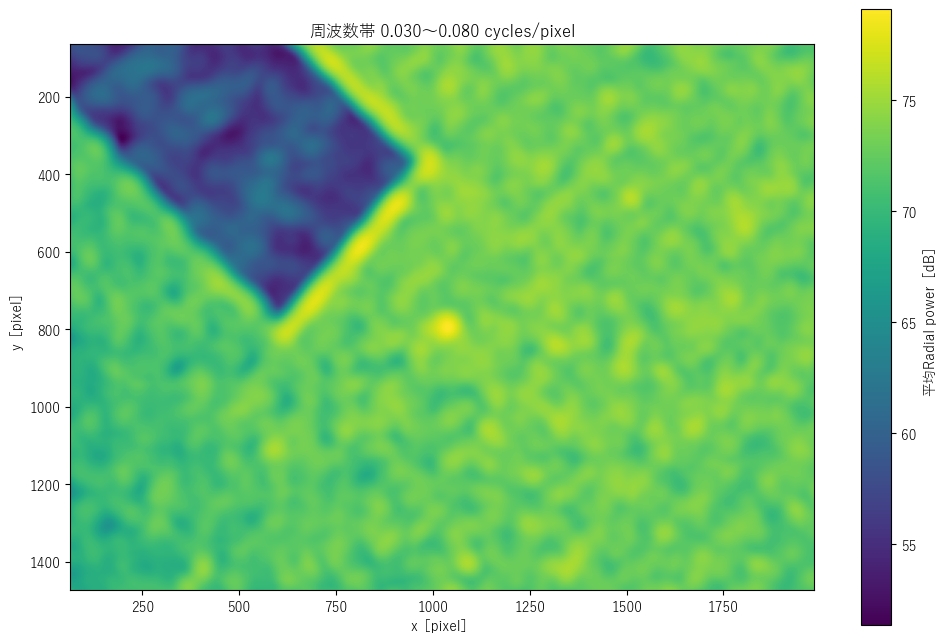

In [23]:
# 指定周波数帯の2次元パワーマップ
FREQ_LOW = 0.03
FREQ_HIGH = 0.08

freq_mask = (
    (frequency_axis >= FREQ_LOW)
    &
    (frequency_axis <= FREQ_HIGH)
)

band_map = feature_map[:, :, freq_mask].mean(axis=2)

plt.figure(figsize=(12, 8))

plt.imshow(
    band_map,
    origin="upper",
    extent=[
        x_centers[0],
        x_centers[-1],
        y_centers[-1],
        y_centers[0]
    ],
    aspect="equal"
)

plt.colorbar(label="平均Radial power［dB］")
plt.xlabel("x［pixel］")
plt.ylabel("y［pixel］")
plt.title(
    f"周波数帯 {FREQ_LOW:.3f}〜{FREQ_HIGH:.3f} cycles/pixel"
)

plt.show()


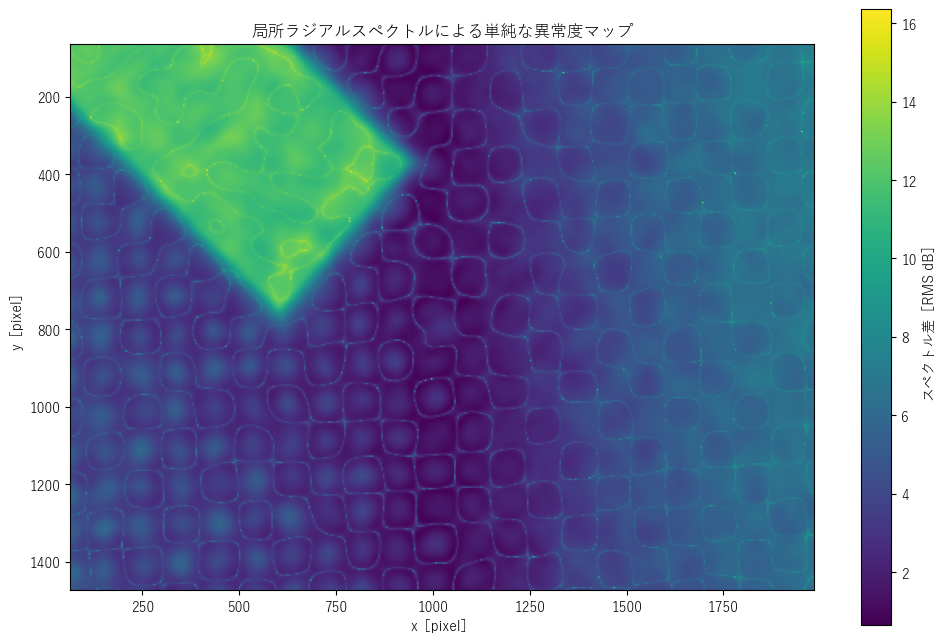

In [24]:
# 全位置の中央値スペクトルを基準とした簡単な異常度マップ
reference_spectrum = np.median(
    feature_map.reshape(-1, N_RADIAL_BINS),
    axis=0
)

difference = (
    feature_map
    -
    reference_spectrum[None, None, :]
)

anomaly_map = np.sqrt(
    np.mean(
        difference ** 2,
        axis=2
    )
)

plt.figure(figsize=(12, 8))

plt.imshow(
    anomaly_map,
    origin="upper",
    extent=[
        x_centers[0],
        x_centers[-1],
        y_centers[-1],
        y_centers[0]
    ],
    aspect="equal"
)

plt.colorbar(label="スペクトル差［RMS dB］")
plt.xlabel("x［pixel］")
plt.ylabel("y［pixel］")
plt.title("局所ラジアルスペクトルによる単純な異常度マップ")

plt.show()


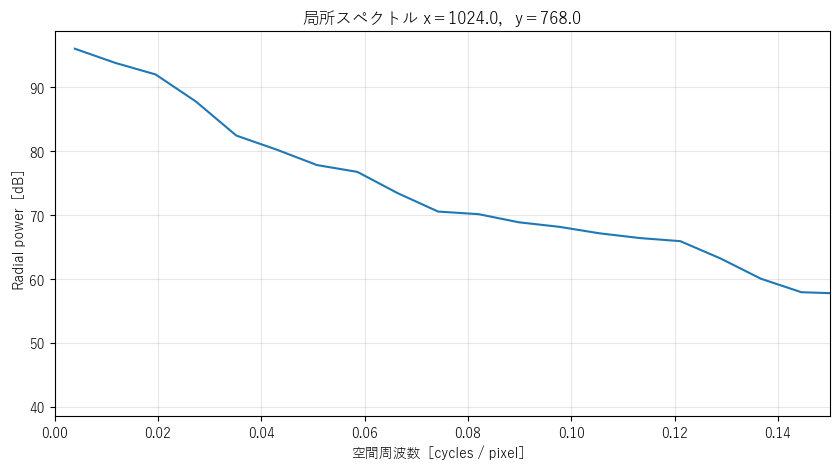

In [27]:
# 任意位置の特徴ベクトルを確認
iy = len(y_centers) // 2
ix = len(x_centers) // 2

local_spectrum = feature_map[iy, ix, :]

plt.figure(figsize=(10, 5))

plt.plot(
    frequency_axis,
    local_spectrum
)

plt.xlim(0, DISPLAY_FREQ_MAX)

plt.xlabel("空間周波数［cycles / pixel］")
plt.ylabel("Radial power［dB］")
plt.title(
    f"局所スペクトル x＝{x_centers[ix]:.1f}，y＝{y_centers[iy]:.1f}"
)

plt.grid(alpha=0.3)
plt.show()
